# Figure 5E and Supp. 6O, 6P, 7F — does adding a module pair help the model?

Scores every ComBVAE model in `ComboKOModels.csv` against the observed
combination effects, and compares the variants by what they were trained on:
single modules alone (`K_singles`), plus one module pair (`K1K3`, `K2K3`), or
plus both (`K2K3_K1K3`).

| Section | Writes |
|---|---|
| Explained variance per module pair | nothing — the original's `pdf()` is commented out, Supp. 6O |
| The three pairs on their own | nothing — likewise, Supp. 6P |
| At the chosen KL weight | `figures/S_7F.pdf`, `figures/Figure_5E.pdf` |

## Setup

In [1]:
source("../paths.R")   # SCREEN_DATA, REFERENCE, TEXTFILES; see data/README.md

# NOTE: Main.R is deliberately not sourced. It loads ICtest, whose Ops method
# conflicts with the S7 objects in ggplot2 4.x and breaks every "+" chain.
# Conf.R and Utilities.R are not sourced either -- nothing below uses their
# paths, and the two helpers are inlined here.
library(ggplot2)
library(data.table)   # before reshape2: both define melt()
library(reshape2)
library(stringr)
library(ggpubr)

`%ni%` <- Negate(`%in%`)

computeR2 <- function(response, prediction) {
    rss <- sum((response - prediction)^2, na.rm = TRUE)       # residual sum of squares
    tss <- sum((response - mean(response, na.rm = TRUE))^2)   # total sum of squares
    1 - rss / tss
}

# Modules are keyed by their K names in every saved table, so the subsets below
# index with those; the M names are applied only where a panel is labelled.
MODULE_OF_K <- c(K0 = "M2", K1 = "M3", K2 = "M6", K3 = "M5", K4 = "M1", K5 = "M4")

moduleLabel <- function(x) {
    for (k in names(MODULE_OF_K)) x <- gsub(k, MODULE_OF_K[[k]], x, fixed = TRUE)
    x
}

# Keeps the panel order the K names gave, so the figures stay comparable.
groupLabel <- function(group) {
    factor(moduleLabel(group), levels = moduleLabel(sort(unique(group))))
}


Attaching package: ‘reshape2’


The following objects are masked from ‘package:data.table’:

    dcast, melt




## Model scores

`allR2s` is read from the screen's data root. It holds explained variance and
mean absolute error per module pair for each of 468 models, with the `SubFolder`
recording which variant produced it.

Building it reads one prediction table per model and takes well over half an
hour, so the saved result is used. The code that produced it is below,
commented out, ending with the `saveRDS` that wrote the file.

Two things to know about that file. Its MAE column does not reproduce exactly
from the commented code, though every R2 does — and only R2 reaches a panel
here, so nothing drawn below depends on it. And it covers 468 of the 489 models
listed; the 21 absent ones are the whole `additiveModel` subfolder, a different
model class rather than dropped rows.

In [2]:
R2_TABLE <- screenPath("ManuscriptFigures", "RDSFiles", "allR2s.rds")
allR2s   <- readRDS(R2_TABLE)

c(rows = nrow(allR2s), models = length(unique(allR2s$Model)))

rows models 
  9828    468

In [3]:
# How allR2s was produced. Left commented: it needs the model directories under
# the data root, and takes well over half an hour.

# models= read.csv(file.path(REFERENCE, "ComboKOModels.csv"))

# # Written by ../combinatorial_perturbations/01-05 and committed there, so this
# # notebook runs from a clone without regenerating them. A re-run of those
# # notebooks writes to their outputs/ and leaves these untouched.
# COMBO_DIR <- "../combinatorial_perturbations/RDSFiles"
#
# combosObserved <- readRDS(file.path(COMBO_DIR, "ComboEffects_lm_residuals.rds"))
# combosObserved <- combosObserved[combosObserved$term %ni% c("(Intercept)", "n_genes", "mt_frac", paste0("leiden", 1:9)),]
# combosObserved[,c("std.error", "statistic", "p.value")] = NULL
# combosObserved$term <- sapply(combosObserved$term,
#                               function(x){str_replace_all(x, "_", "")})
# colnames(combosObserved) = c("Group", "ObservedLogFCEstimate", "respGene")
#
#
# combosInterP <- readRDS(file.path(COMBO_DIR, "ComboEffects_lm_residuals_withInteractions.rds"))
# combosInterP <- combosInterP[combosInterP$term %ni% c("(Intercept)", "n_genes", "mt_frac", paste0("leiden", 1:9)),]
# combosInterP = data.table(combosInterP)
# combosInterP[,FDR:=p.adjust(p.value, method = "fdr", n = length(p.value)),by=respGene]
# combosInterP = data.frame(combosInterP)
# combosInterP$term <- sapply(combosInterP$term,
#                             function(x){str_replace_all(as.character(x),"_","")})
# combosInterP$term <- sapply(combosInterP$term,
#                             function(x){str_replace_all(as.character(x),":","W")})
# combosInterP <- combosInterP[,c("term", "FDR", "respGene")]
# colnames(combosInterP) = c("Group", "FDRInteraction", "respGene")
#

# combosObserved = merge(combosObserved,combosInterP, by=c("Group", "respGene"))

# options(repr.plot.width=12, repr.plot.height=12)
# allR2s = data.frame()
# allSgnR2s = data.frame()
#
# for( i in 1:nrow(models)){
#
#         allResDF = read.csv(paste0(projectDir, "/Notebooks/CombinatorialPerturbations/outputs/",
#                                    models[i,"SubFolder"],
#                                    "/",
#                                    models[i,"Model_Name"],
#                                    "/PredictedFC_Coef.csv"))
#
#
#         allResDF = allResDF[allResDF$X != "intercept",]
#         allResDF = melt(allResDF)
#         colnames(allResDF) = c("Group","respGene","PredictedLogFCEstimate")
#         allResDF$Group = sapply(allResDF$Group,
#                                 function(x){strsplit(x, "perturb_")[[1]][2]})
#         allResDF$Group = sapply(allResDF$Group,
#                                 function(x){str_replace(x, "_", "W")})
#         allResDF$alpha = models[i,"Alpha"]
#         allResDF$SubFolder = models[i,"SubFolder"]
#
#
#
#         allRes = merge(combosObserved, allResDF , by=c("Group", "respGene"))
#         allRes = data.table(allRes)
#         allRes[,R2:=round(computeR2(response = ObservedLogFCEstimate,
#                                     prediction = PredictedLogFCEstimate),
#                           digits=2),by=Group]
#         allRes[,MAE:=round(mean(abs(PredictedLogFCEstimate - ObservedLogFCEstimate )), digits=2),by=Group]
#         allRes = data.frame(allRes)
#
#         #head(allResDF, n=50)
#
#         allRes$Group1 = sapply(allRes$Group,
#                                function(x){return(strsplit(as.character(x),"W")[[1]][1]) })
#         allRes$Group2 = sapply(allRes$Group,
#                                function(x){return(strsplit(as.character(x),"W")[[1]][2]) })
#         allRes$ObsPredDif = allRes$ObservedLogFCEstimate - allRes$PredictedLogFCEstimate
#         #allRes$AbsObsPredDif = abs(allRes$ObservedLogFCEstimate - allRes$PredictedLogFCEstimate)
#         allRes$GroupGene = paste0(allRes$Group,"_",allRes$respGene)
#         allRes[is.na(allRes$Group2),"Group2"] = allRes[is.na(allRes$Group2),"Group1"]
#
#         myTmp = unique(allRes[,c("R2","MAE","Group1","Group2","alpha","SubFolder")])
#         myTmp$Model = models[i,"Model_Name"]
#
#
#         allR2s = rbind(allR2s, myTmp)
#
#         # options(repr.plot.width=10, repr.plot.height=10)
#         # print(ggplot(allRes, aes(x=PredictedLogFCEstimate, y=ObservedLogFCEstimate)) +
#         #     geom_point(alpha=0.4, shape=20, color="blue") +
#         #     facet_grid(Group1 ~ Group2)+
#         #     geom_text(aes(label= paste0("R^2 = ",R2), color="red"), x=0, y=-0.3, size=5)+
#         #     geom_text(aes(label= paste0("MAE = ",MAE), color="red"), x=0, y=-0.5, size=5)+
#         #     geom_abline(linetype="dashed")+
#         #     theme_minimal()+
#         #     theme(axis.text = element_text(size = 15),
#         #           axis.title = element_text(size = 25),
#         #           strip.text = element_text(size = 25), legend.position='none')+
#         #     xlim(-0.6,0.6)+ylim(-0.6,0.6)+
#         #     ylab("Observed fold change wrt control (lg2)")+
#         #     xlab("Predicted fold change wrt control (lg2)")+ggtitle(models[i,"Model_Name"]))
#
#
#
#         geneDE = allRes[allRes$Group %ni% c("K0", "K1", "K2", "K3", "K4", "K5"),]
#         geneDE = geneDE[geneDE$FDRInteraction < 0.1,]
#         geneDE = data.table(geneDE)
#
#         geneDE[,SignR2 := computeR2(response = ObservedLogFCEstimate, prediction = PredictedLogFCEstimate),by=Group]
#         geneDE[,SignMAE:=round(mean(abs(PredictedLogFCEstimate - ObservedLogFCEstimate )), digits=2),by=Group]
#
#         myTmp2 = unique(geneDE[,c("SignR2","SignMAE","Group1","Group2","alpha","SubFolder")])
#         myTmp2$Model = models[i,"Model_Name"]
#         myTmp2$SubFolder = models[i,"SubFolder"]
#
#
#         allSgnR2s = rbind(allSgnR2s, myTmp2)
#
# #         options(repr.plot.width=10, repr.plot.height=10)
# #         print(ggplot(geneDE, aes(x=PredictedLogFCEstimate, y=ObservedLogFCEstimate)) +
# #         geom_point(alpha=0.4, shape=20, color="blue") +
# #         facet_grid(Group1 ~ Group2)+
# #         geom_text(aes(label= paste0("MAE = ",SignMAE), color="red"), x=0, y=-0.3, size=7)+
# #         geom_abline(linetype="dashed")+
# #         theme_minimal()+
# #         theme(axis.text = element_text(size = 15),
# #               axis.title = element_text(size = 25),
# #               strip.text = element_text(size = 25), legend.position='none')+
# #         geom_vline(xintercept = 0, linetype="dashed", color="red")+
# #         geom_hline(yintercept = 0, linetype="dashed", color="red")+
# #         xlim(-0.4,0.4)+ylim(-0.4,0.4)+
# #         ylab("Observed fold change wrt control (lg2)")+
# #         xlab("Predicted fold change wrt control (lg2)")+ggtitle(model))
#
# }

# saveRDS(allR2s, R2_TABLE)

In [4]:
allR2sCombos = allR2s[allR2s$SubFolder != "K_singles",]
allR2sSingles = allR2s[allR2s$SubFolder == "K_singles",]

In [5]:
allR2sSingles = allR2sSingles[allR2sSingles$alpha %in% unique(allR2sCombos$alpha),]

In [6]:
allR2s_sel = rbind(allR2sCombos, allR2sSingles)

In [7]:
allR2s_sel$Group = paste0(allR2s_sel$Group1,"_",allR2s_sel$Group2)

# Both were mapped by the panels and assigned by no cell -- lost in the port,
# the same way they were in Figure 5F. alpha is the KL loss weight, discrete.
allR2s_sel$alphaFactor <- factor(allR2s_sel$alpha)
allR2s_sel$GroupLabel  <- groupLabel(allR2s_sel$Group)


In [8]:
allR2s_sel$SubFolder = factor(allR2s_sel$SubFolder, 
                              levels=c("K_singles", "K1K3", "K2K3", "K2K3_K1K3"))

# What each model variant was trained on, in module names. K_singles is the
# single modules alone; the others add one or both module pairs.
SUBFOLDER_LABELS <- c(K_singles = "singles",
                      K1K3      = "M3+M5",
                      K2K3      = "M6+M5",
                      K2K3_K1K3 = "M6+M5 and M3+M5")

allR2s_sel$SubFolderLabel <- factor(SUBFOLDER_LABELS[as.character(allR2s_sel$SubFolder)],
                                    levels = unname(SUBFOLDER_LABELS))


In [9]:
allR2s_sel = data.table(allR2s_sel)

In [10]:
allR2s_sel$SubFolderAlpha = paste0(allR2s_sel$SubFolder,"_" ,allR2s_sel$alpha)

In [11]:
allR2s_sel[,meanR2 := mean(R2),by=SubFolderAlpha]
allR2s_sel = data.frame(allR2s_sel)

In [12]:
allR2s_sel = allR2s_sel[allR2s_sel$Group %ni% c("K0_K0", "K1_K1", "K2_K2", "K3_K3", "K4_K4", "K5_K5"),]

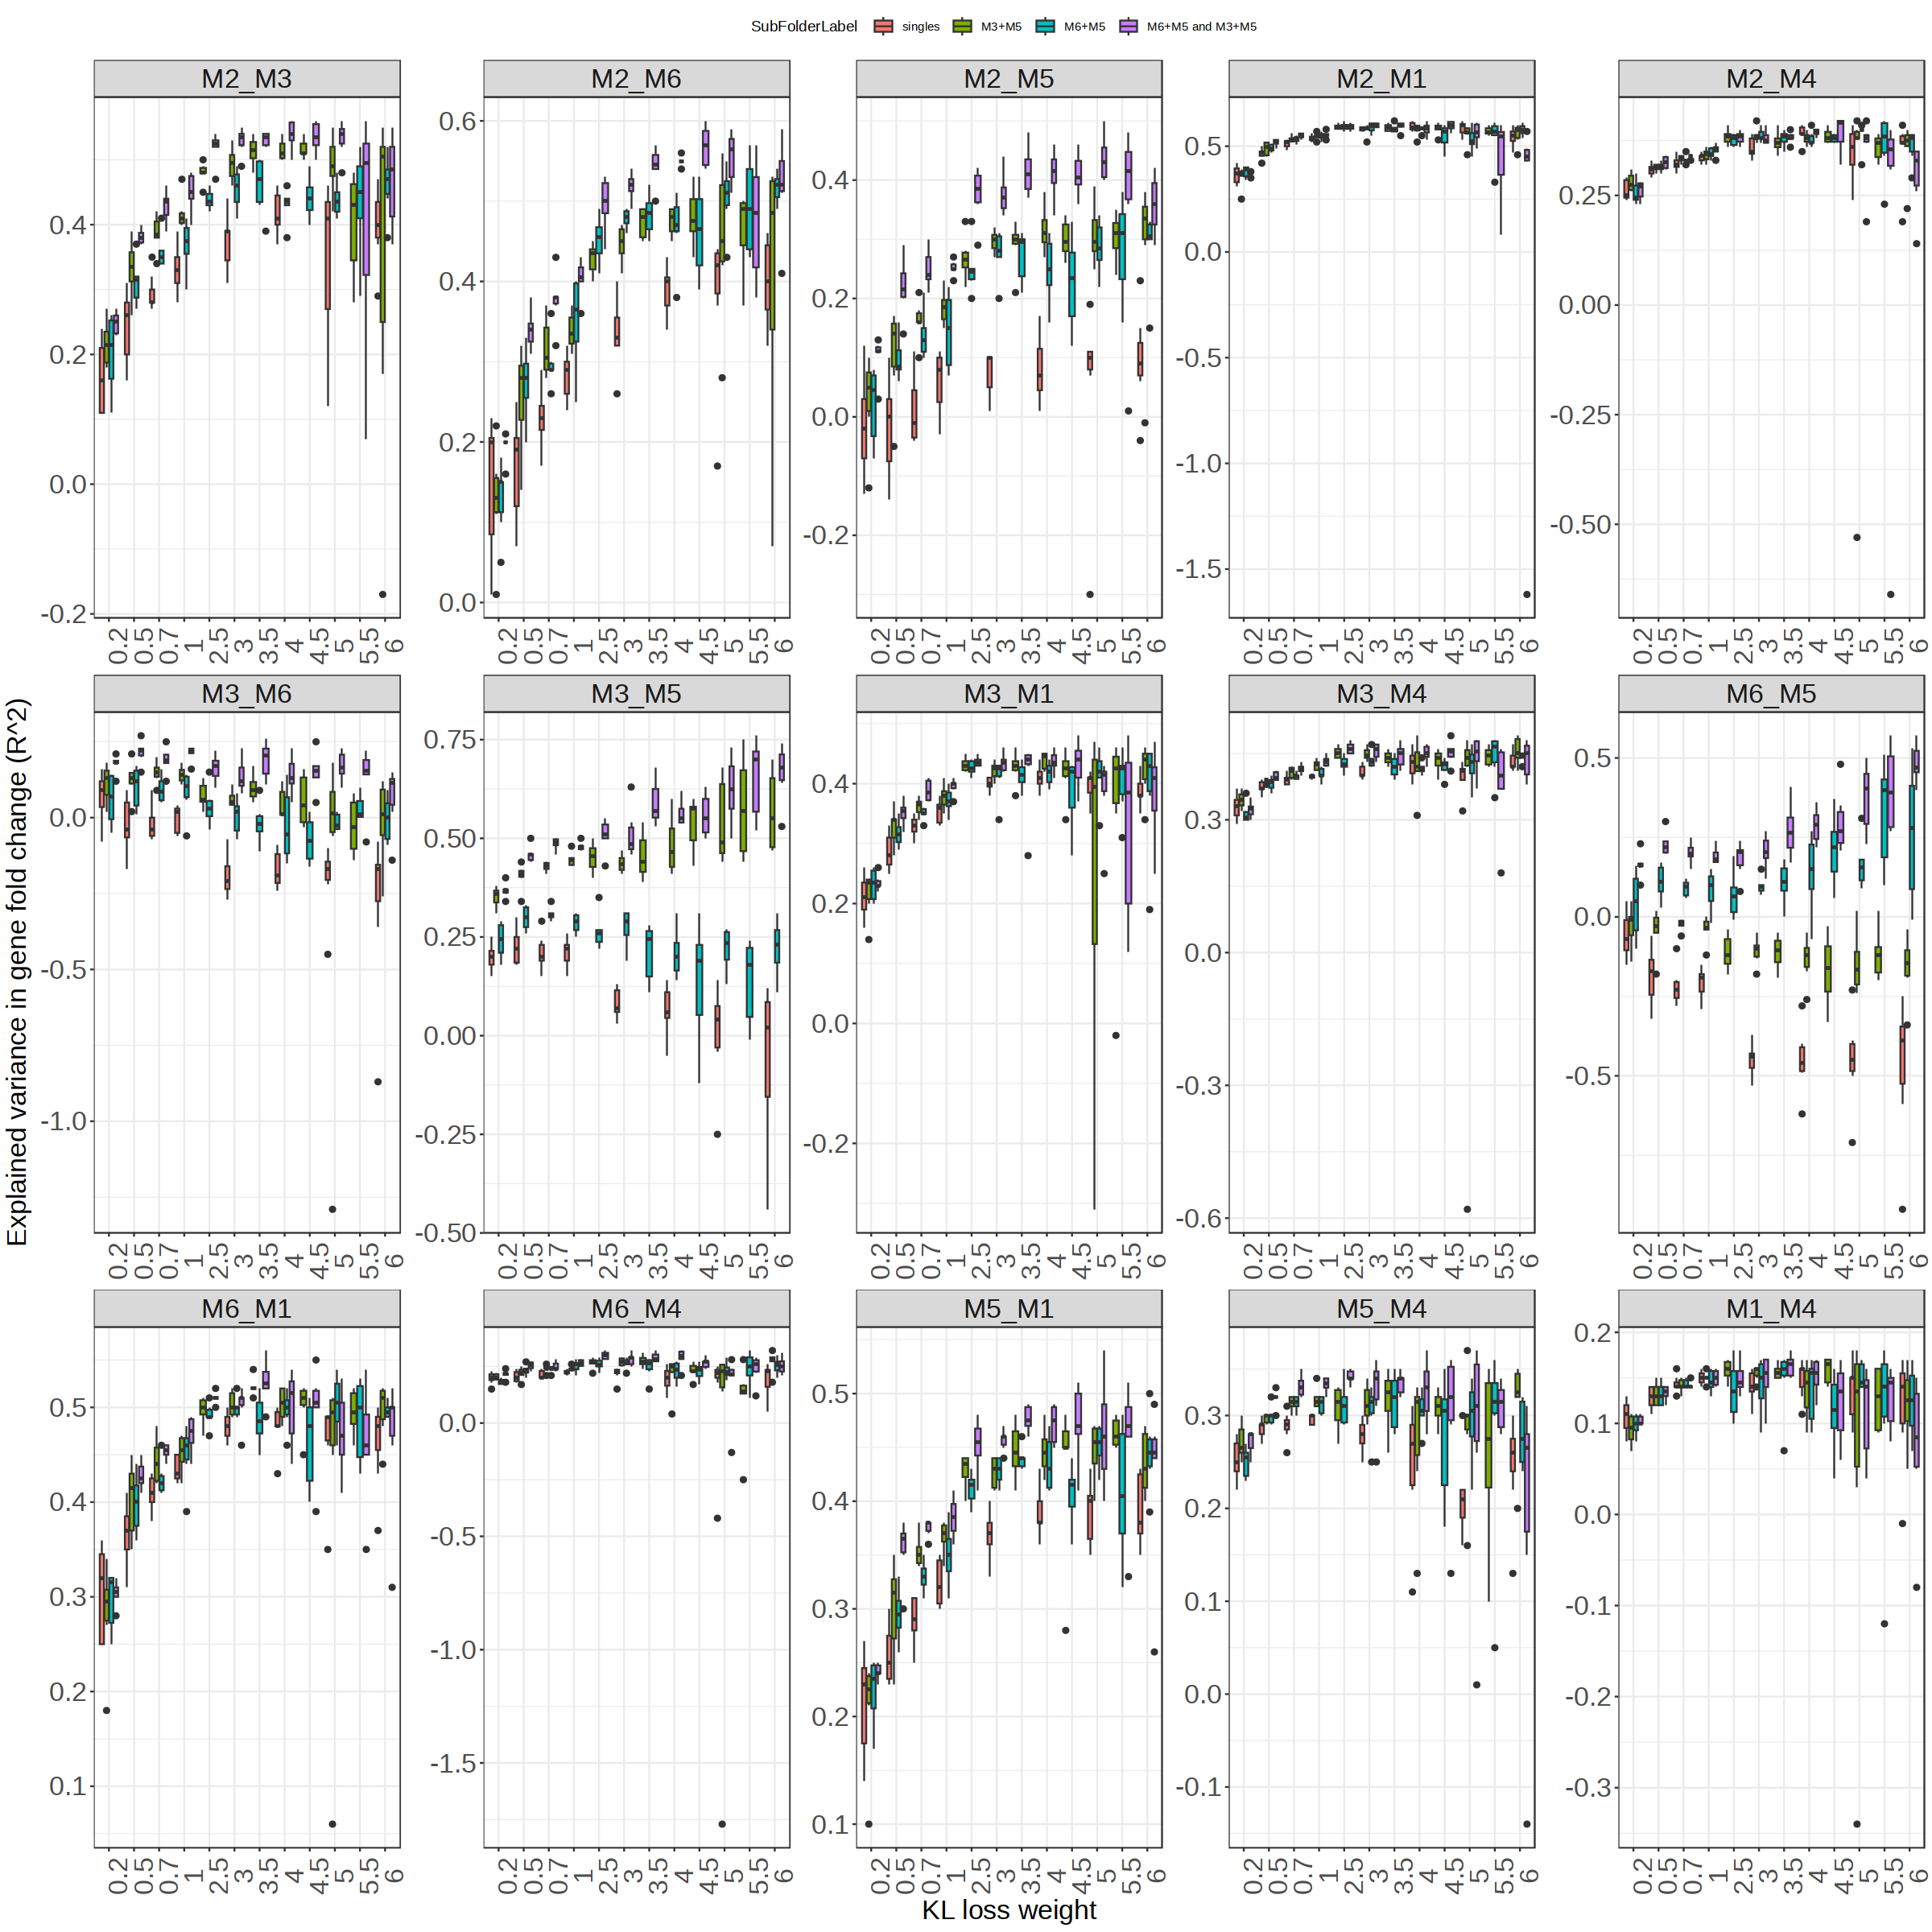

In [13]:
options(repr.plot.width=20, repr.plot.height=20)
#pdf("./../SupplementaryFigures/S_6O.pdf", width = 20, height = 20)
ggplot(data=allR2s_sel, aes(x=alphaFactor, y=R2,  fill=SubFolderLabel)) +
  facet_wrap(~GroupLabel, scales="free", ncol=5)+
  geom_boxplot()+
  theme_bw()+theme(axis.text.x = element_text(size = 20, angle=90),
                   axis.text.y = element_text(size = 20),
                   axis.title = element_text(size = 20),
                   strip.text=element_text(size = 20),
                   legend.position="top")+ylab("Explained variance in gene fold change (R^2)")+
                   #stat_compare_means(method = "wilcox.test", comparisons = cList)+
                   xlab("KL loss weight")

#dev.off()

In [14]:
allR2s_sel_subset = allR2s_sel[allR2s_sel$Group %in% c("K1_K2", "K1_K3", "K2_K3"),]

Warning message in wilcox.test.default(c(0.09, 0.13, 0, -0.08, 0.16, 0.11, 0.07), :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.03, -0.07, -0.14, -0.15, 0.05, -0.05, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.12, 0.14, 0.06, 0.16, 0.18, 0.02), c(0.12, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.36, 0.36, 0.37, 0.31, 0.38, 0.33), c(0.7, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(-0.02, 0, -0.14, 0.05, 0, -0.07), c(-0.1, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(-0.01, 0.13, 0.14, -0.05, 0.14, 0.01), :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.2, 0.24, 0.29, 0.18, 0.29, 0.25), c(0.27, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(-0.02, 0.16, 0.12, -0.05, 0.12, -0.1), :
“cannot compute exact p-value with 

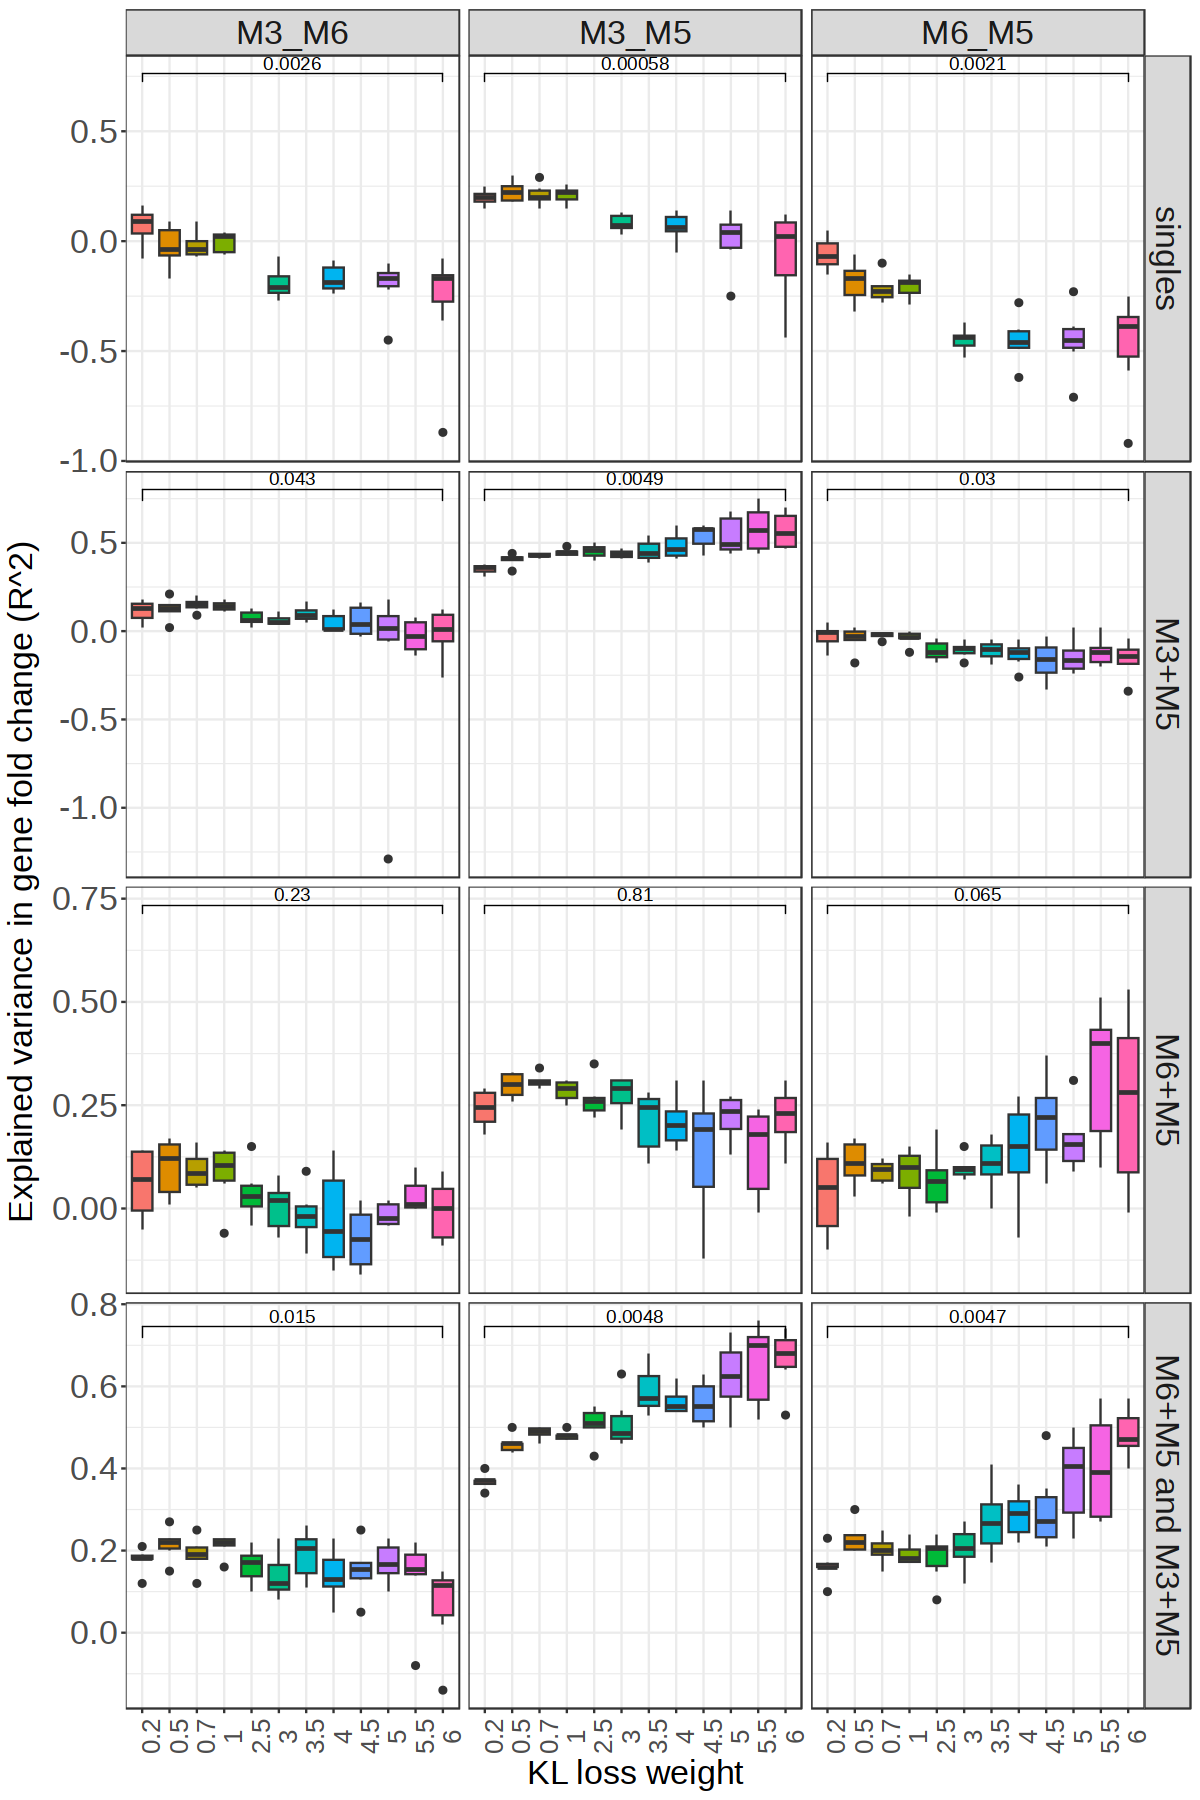

In [15]:
options(repr.plot.width=10, repr.plot.height=15)
cList = list(c("0.2", "6"))

#pdf("./../SupplementaryFigures/S_6P.pdf", width = 10, height = 15)
ggplot(data=allR2s_sel_subset, aes(x=alphaFactor, y=R2, group=alphaFactor, fill=alphaFactor)) +
  facet_grid(SubFolderLabel~GroupLabel, scales="free")+
  geom_boxplot()+
  theme_bw()+theme(axis.text.x = element_text(size = 15, angle=90),
                   axis.text.y = element_text(size = 20),
                   axis.title = element_text(size = 20),
                   strip.text=element_text(size = 20),
                   legend.position="none")+ylab("Explained variance in gene fold change (R^2)")+
                   stat_compare_means(method = "wilcox.test", comparisons = cList, label.y = c(0.7))+
                   xlab("KL loss weight")
#dev.off()

In [16]:
allR2s_sel_alpha6 = allR2s_sel[allR2s_sel$alpha == 6,]

In [17]:
allR2s_sel_alpha6 = allR2s_sel_alpha6[allR2s_sel_alpha6$Group %ni% c("K0_K0", "K1_K1","K2_K2","K3_K3", "K4_K4","K5_K5"),]

In [18]:
allR2s_sel_alpha6_sel_1 = allR2s_sel_alpha6[allR2s_sel_alpha6$Group %ni% c("K0_K1","K0_K2", "K0_K3", "K1_K2",
                                                                         "K1_K3","K1_K4","K2_K3","K3_K4"),]

agg_record_1488234072 
                    2

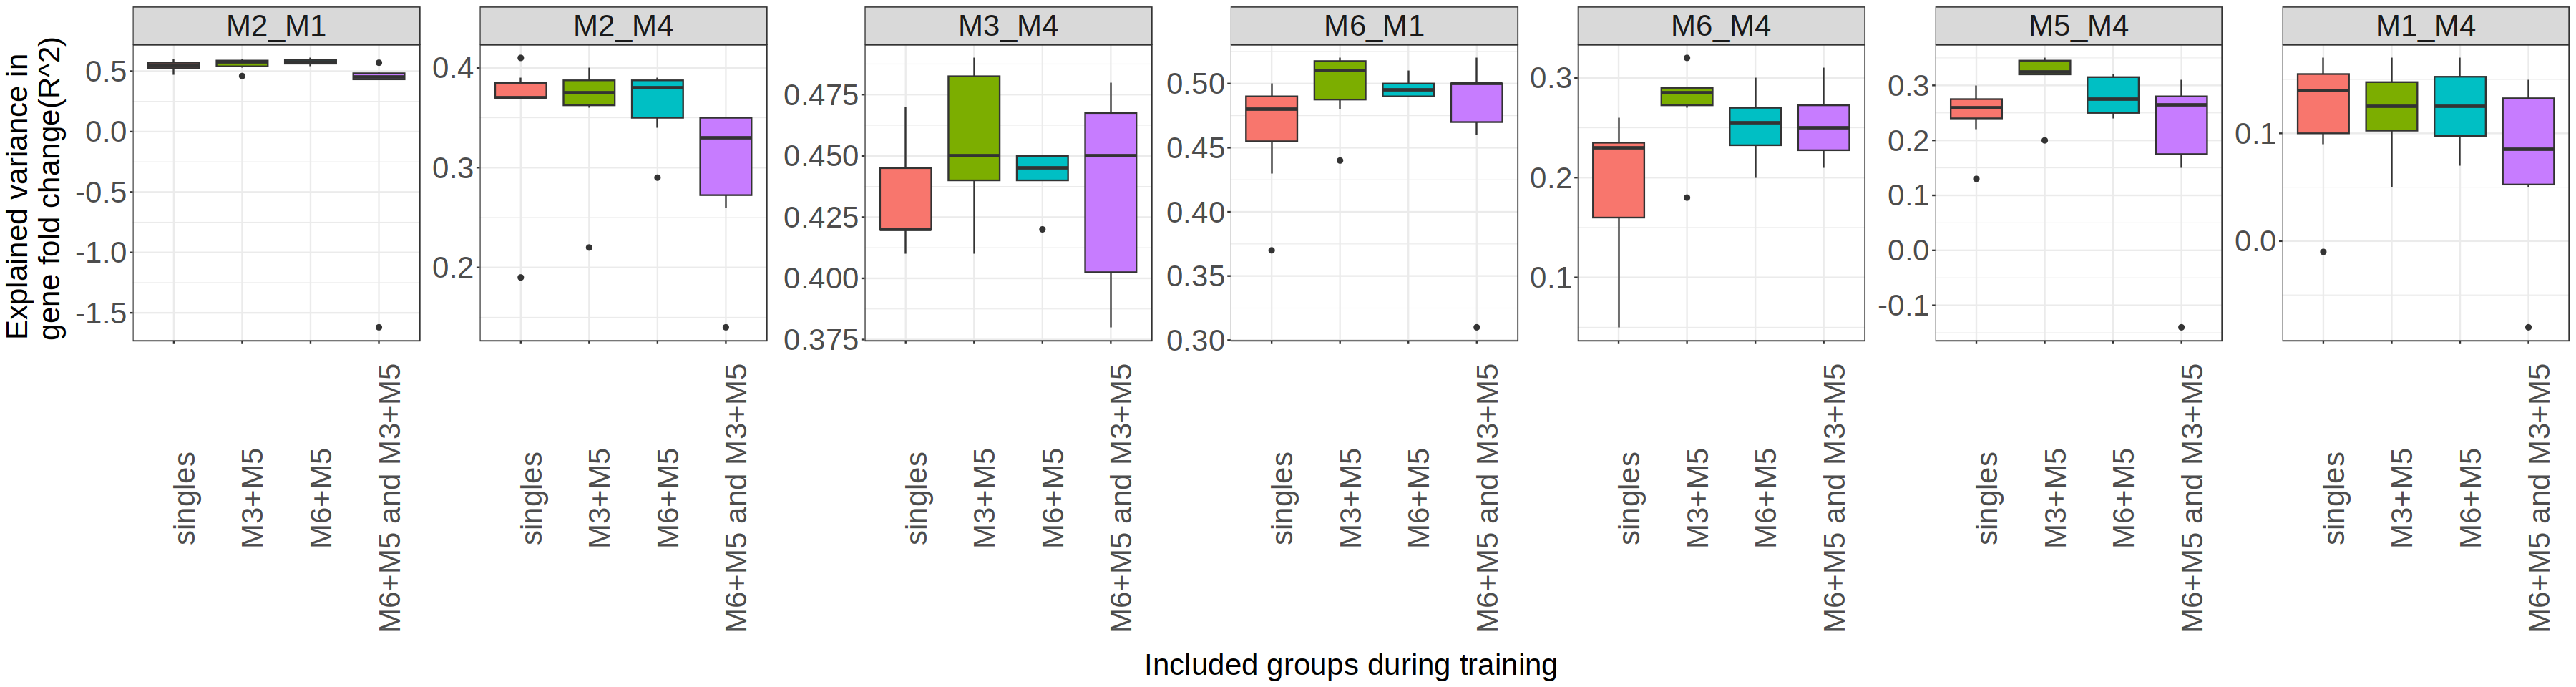

In [19]:
options(repr.plot.width=30, repr.plot.height=8)
cList = list(c("singles", "M3+M5"), c("singles", "M6+M5"), c("singles", "M6+M5 and M3+M5"))

p <- ggplot(data=allR2s_sel_alpha6_sel_1, aes(x=SubFolderLabel, y=R2, group=SubFolderLabel, fill=SubFolderLabel)) +
  facet_wrap(~GroupLabel, scales="free", nrow = 1)+
  geom_boxplot()+
  theme_bw()+theme(axis.text.x = element_text(size = 25, angle=90),
                   axis.text.y = element_text(size = 25),
                   axis.title = element_text(size = 25),
                   strip.text=element_text(size = 25),
                   legend.position="none")+ylab("Explained variance in \n gene fold change(R^2)")+
                   #stat_compare_means(method = "wilcox.test", comparisons = cList)+
                   xlab("Included groups during training")

pdf("figures/S_7F.pdf", width = 30, height = 8)
print(p)
dev.off()

p   # show it in the notebook as well as saving it

In [20]:
allR2s_sel_alpha6_sel = allR2s_sel_alpha6[allR2s_sel_alpha6$Group %in% c("K0_K1","K0_K2", "K0_K3", "K1_K2", "K1_K3","K1_K4","K2_K3","K3_K4"),]

agg_record_256605470 
                   2

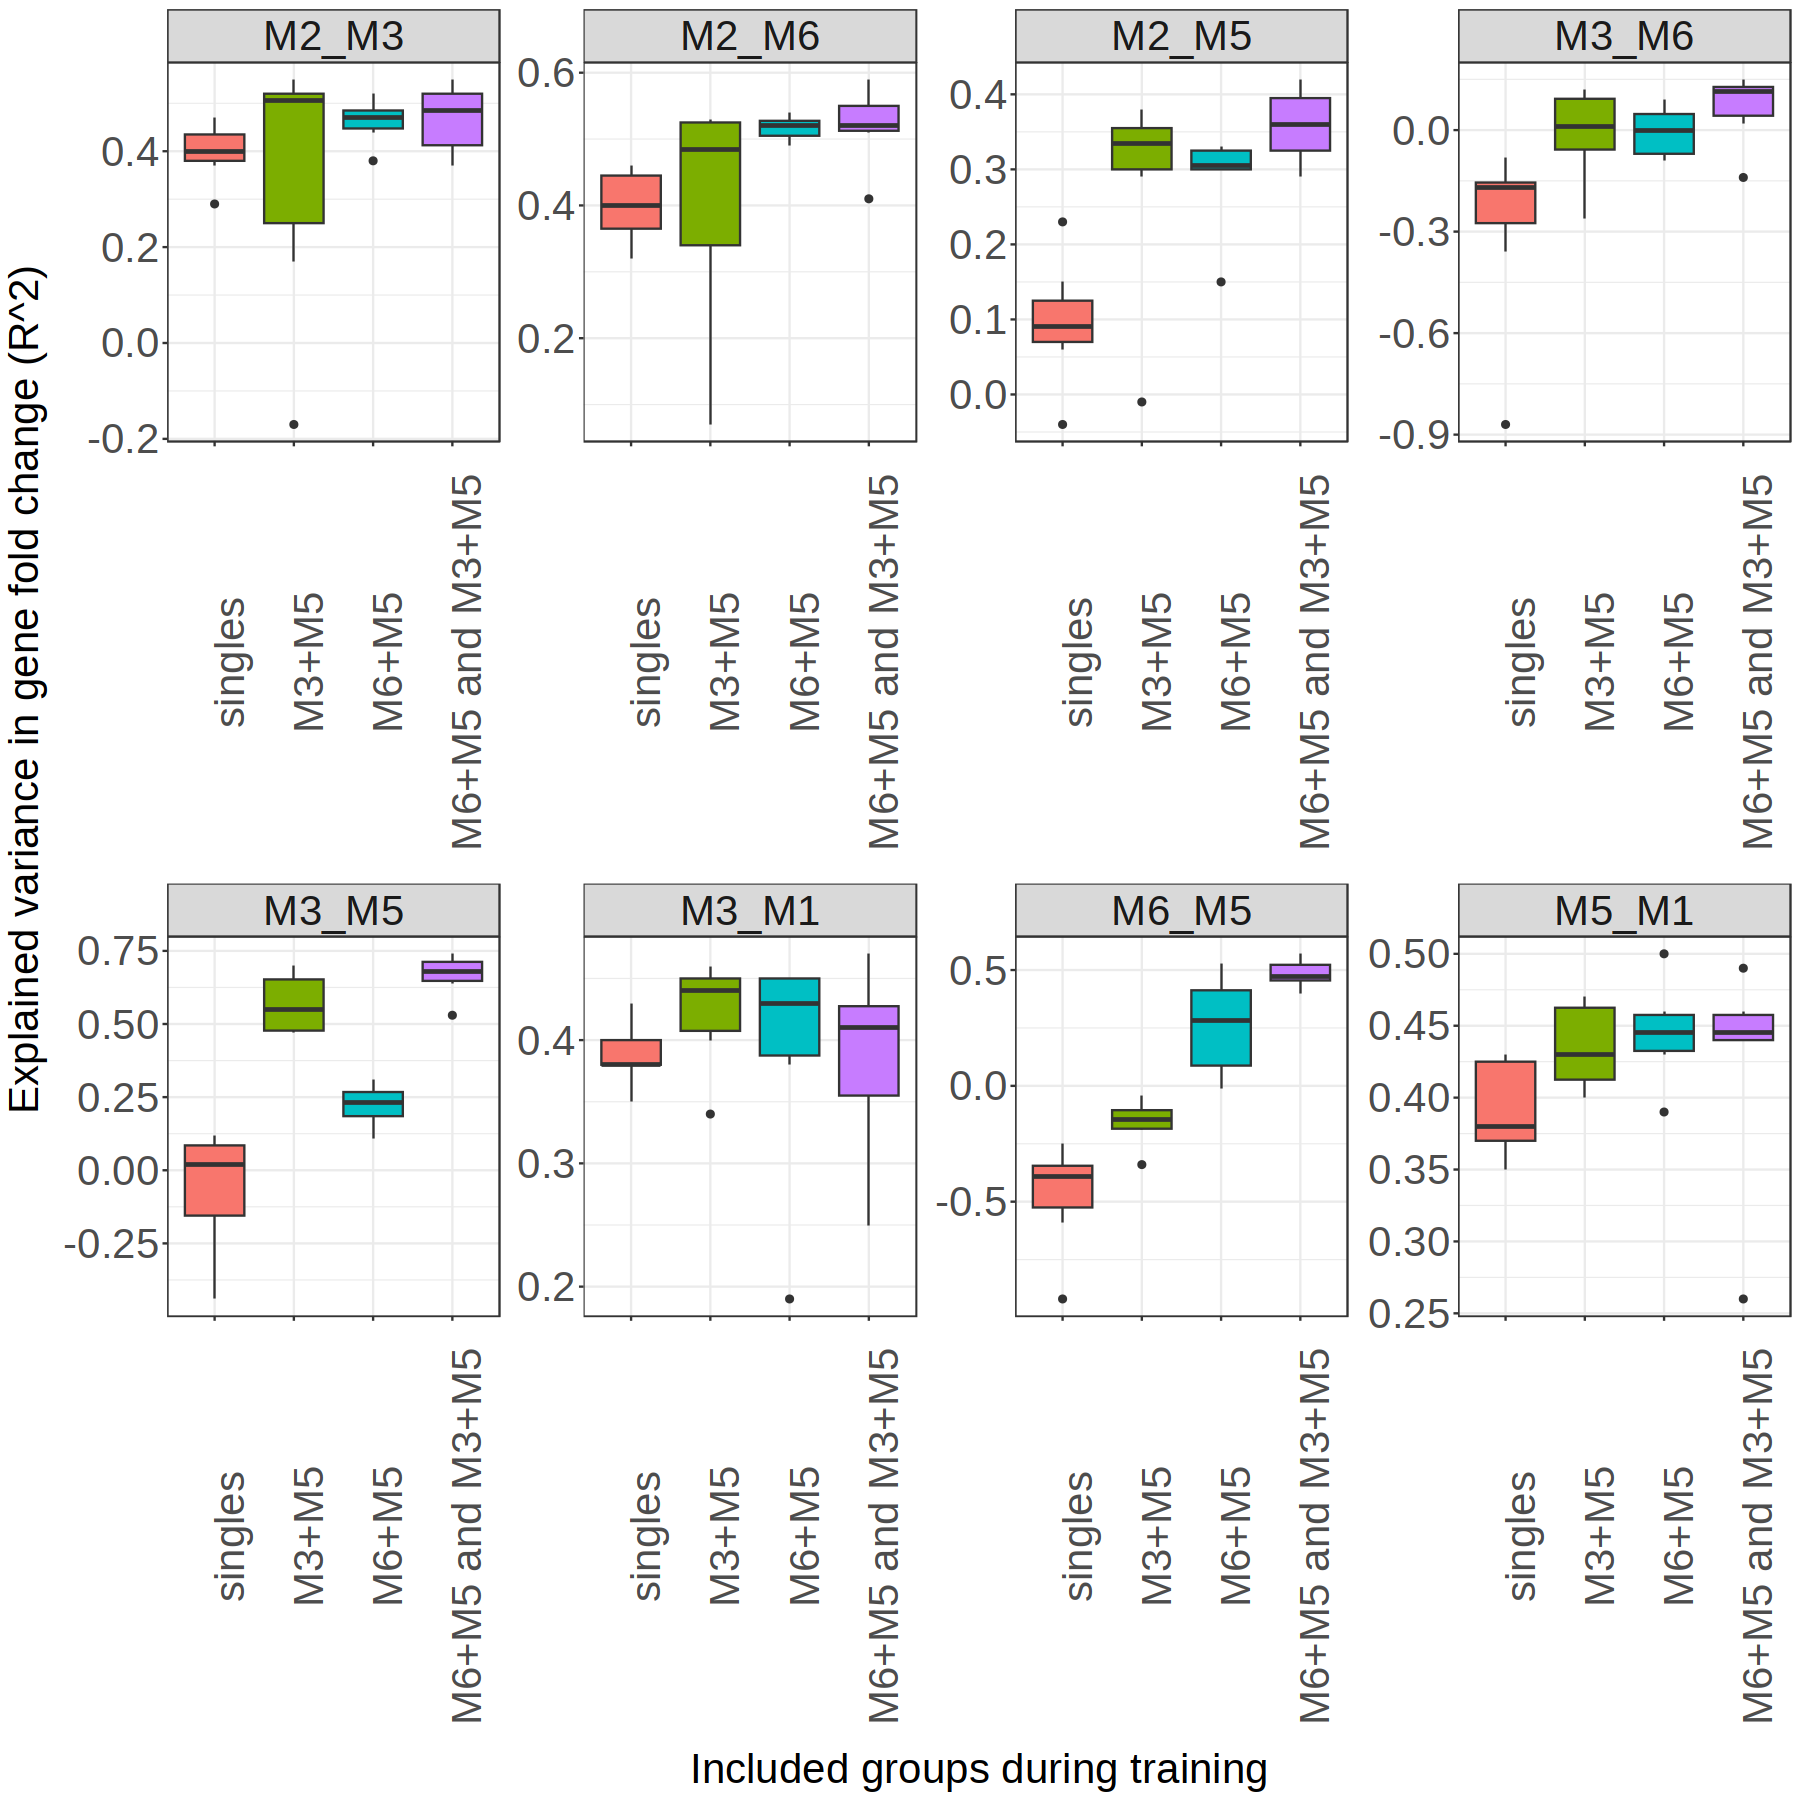

In [21]:
options(repr.plot.width=15, repr.plot.height=15)
cList = list(c("singles", "M3+M5"), c("singles", "M6+M5"), c("singles", "M6+M5 and M3+M5"))

p <- ggplot(data=allR2s_sel_alpha6_sel, aes(x=SubFolderLabel, y=R2, group=SubFolderLabel, fill=SubFolderLabel)) +
  facet_wrap(~GroupLabel, scales="free", ncol = 4)+
  geom_boxplot()+
  theme_bw()+theme(axis.text.x = element_text(size = 25, angle=90),
                   axis.text.y = element_text(size = 25),
                   axis.title = element_text(size = 25),
                   strip.text=element_text(size = 25),
                   legend.position="none")+ylab("Explained variance in gene fold change (R^2)")+
                   #stat_compare_means(method = "wilcox.test", comparisons = cList)+
                   xlab("Included groups during training")

pdf("figures/Figure_5E.pdf", width=15, height=15)
print(p)
dev.off()

p   # show it in the notebook as well as saving it